# Free-Energy Principle:

### Objective
This code provides a simplified computational demonstration of Friston's Free-Energy Principle using a Gaussian generative model and gradient-based free-energy minimization:

1. A system has a hidden state.
2. The hidden state generates predictions about sensory observations.
3. Sensory observations are compared with predictions.
4. Prediction errors contribute to variational free energy.
5. The hidden state is updated using gradient descent.
6. Free energy is recalculated to show its reduction at every step.

The goal is to demonstrate perceptual inference through free-energy minimization.

## 1. Generative Model

Friston's framework assumes that sensory observations are generated by hidden
causes or states of the environment.

A simplified generative model is:

$$
y = Wx + z
$$

where:

- $y$ = sensory observation
- $x$ = hidden state
- $W$ = generative model
- $z$ = sensory noise

The brain does not directly observe the hidden state $x$. Instead, it receives
sensory data $y$ and attempts to infer the hidden state that could have
generated that data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Generative model
W = 2.0

# Actual hidden state of the environment
true_state = 3.0

# Sensory noise
sensory_noise = 0.5

# Generate sensory observations
observations = (
    W * true_state
    + np.random.normal(0, sensory_noise, 30)
)

print("True hidden state:", true_state)
print("First 5 observations:", observations[:5])

True hidden state: 3.0
First 5 observations: [6.24835708 5.93086785 6.32384427 6.76151493 5.88292331]


## 2. Prior Belief and Precision

The system also has a prior belief about the hidden state.

We assume:

$$
x \sim N(\mu, \sigma_x^2)
$$

where $\mu$ is the prior mean.

Precision is the inverse of variance:

$$
\Pi = \frac{1}{\sigma^2}
$$

Higher precision means greater confidence in the corresponding information.

In this implementation we use:

- sensory precision for sensory prediction errors
- prior precision for the prior belief

In [2]:
# Prior belief
prior_mean = 1.0
prior_variance = 1.0

# Precision = inverse of variance (how strongly we trust something)
sensory_precision = 1 / sensory_noise**2
prior_precision = 1 / prior_variance

# Initial estimate of hidden state (deliberately 0, to see whether free-energy minimization can improve this estimate)
x = 0.0

# Learning rate for gradient descent
learning_rate = 0.02

print("Prior mean:", prior_mean)
print("Sensory precision:", sensory_precision)
print("Prior precision:", prior_precision)
print("Initial hidden-state estimate:", x)

Prior mean: 1.0
Sensory precision: 4.0
Prior precision: 1.0
Initial hidden-state estimate: 0.0


## 3. Variational Free Energy

For a simple Gaussian model, we use the following free-energy expression:

$$
F =
\frac{1}{2}\Pi_y(y-Wx)^2
+
\frac{1}{2}\Pi_x(x-\mu)^2
$$

The first term represents the sensory prediction-error contribution.

$$
\frac{1}{2}\Pi_y(y-Wx)^2
$$

The second term represents the difference between the inferred state and
the prior belief.

$$
\frac{1}{2}\Pi_x(x-\mu)^2
$$

Therefore, the system attempts to find an internal state $x$ that provides a
good explanation of the sensory observation while remaining consistent with
its prior belief.

In [3]:
#Calculate simplified variational free energy.
def free_energy(x, y):
    # Prediction generated by the hidden state
    prediction = W * x

    # Prediction error (Large error → high free energy)
    prediction_error = y - prediction

    # Sensory prediction-error term
    sensory_term = (0.5 * sensory_precision * prediction_error**2)

    # Prior term (penalizes the model if its estimate moves too far from its prior belief)
    prior_term = (0.5 * prior_precision * (x - prior_mean)**2)

    # Total free energy
    F = sensory_term + prior_term

    return F

## 4. Perceptual Inference Through Free-Energy Minimization

The hidden state is updated by gradient descent:

$$
x_{new}
=
x_{old}
-
\eta
\frac{\partial F}{\partial x}
$$

For our free-energy function:

$$
\frac{\partial F}{\partial x}
=
-W\Pi_y(y-Wx)
+
\Pi_x(x-\mu)
$$

Thus, the hidden state changes in the direction that reduces free energy.

This represents perceptual inference: the system changes its internal belief
about the hidden cause of its sensory input.

In [ ]:
# 1. Calculate F
# 2. Calculate prediction error
# 3. Update x
# 4. Calculate F again

# Store results
state_history = []
prediction_history = []
prediction_error_history = []

free_energy_before = []
free_energy_after = []
free_energy_reduction = []

# Free-energy minimization loop

for step, y in enumerate(observations):
    # 1. Current prediction
    prediction = W * x

    # 2. Prediction error
    prediction_error = y - prediction

    # 3. Free energy BEFORE update (How much free energy does my current belief produce?)
    F_before = free_energy(x, y)

    # 4. Gradient of free energy (In which direction should x move to reduce Free Energy?)
    dF_dx = (-W * sensory_precision * prediction_error + prior_precision * (x - prior_mean))

    # 5. Gradient descent (system changes its hidden-state belief in the direction that reduces F)
    x_new = x - learning_rate * dF_dx

    # 6. Free energy AFTER update
    F_after = free_energy(x_new, y)

    # Amount of reduction
    reduction = F_before - F_after

    # Store results
    state_history.append(x_new)
    prediction_history.append(prediction)
    prediction_error_history.append(prediction_error)

    free_energy_before.append(F_before)
    free_energy_after.append(F_after)
    free_energy_reduction.append(reduction)

    # Update hidden state
    x = x_new

## 5. Showing Free-Energy Reduction at Every Step

For every observation, the notebook calculates:

$$
F_{before}
$$

then updates the hidden state, and calculates:

$$
F_{after}
$$

The reduction is:

$$
\Delta F =
F_{before}-F_{after}
$$

If:

$$
\Delta F > 0
$$

then the update has reduced free energy.

In [5]:
print("Step | F before | F after | Reduction | Estimated State")
print("-" * 65)

for i in range(len(observations)):
    print(
        f"{i+1:4d} | "
        f"{free_energy_before[i]:8.3f} | "
        f"{free_energy_after[i]:8.3f} | "
        f"{free_energy_reduction[i]:9.3f} | "
        f"{state_history[i]:15.3f}"
    )

Step | F before | F after | Reduction | Estimated State
-----------------------------------------------------------------
   1 |   78.584 |   35.430 |    43.154 |           1.020
   2 |   30.286 |   14.219 |    16.067 |           1.642
   3 |   18.688 |    9.382 |     9.306 |           2.116
   4 |   13.429 |    7.355 |     6.074 |           2.498
   5 |    2.695 |    2.175 |     0.520 |           2.610
   6 |    2.175 |    1.949 |     0.226 |           2.684
   7 |    5.461 |    3.902 |     1.559 |           2.878
   8 |    2.552 |    2.388 |     0.165 |           2.941
   9 |    1.910 |    1.773 |     0.137 |           2.883
  10 |    2.283 |    2.206 |     0.077 |           2.926
  11 |    1.870 |    1.757 |     0.112 |           2.874
  12 |    1.757 |    1.708 |     0.049 |           2.840
  13 |    2.082 |    2.035 |     0.047 |           2.874
  14 |    2.746 |    1.811 |     0.935 |           2.724
  15 |    1.677 |    1.384 |     0.293 |           2.640
  16 |    1.731 |    1.

## 6. Visualization

The following plots show:

1. How the estimated hidden state changes.
2. How prediction error changes.
3. Free energy before and after each update.
4. How much free energy is reduced at each step.

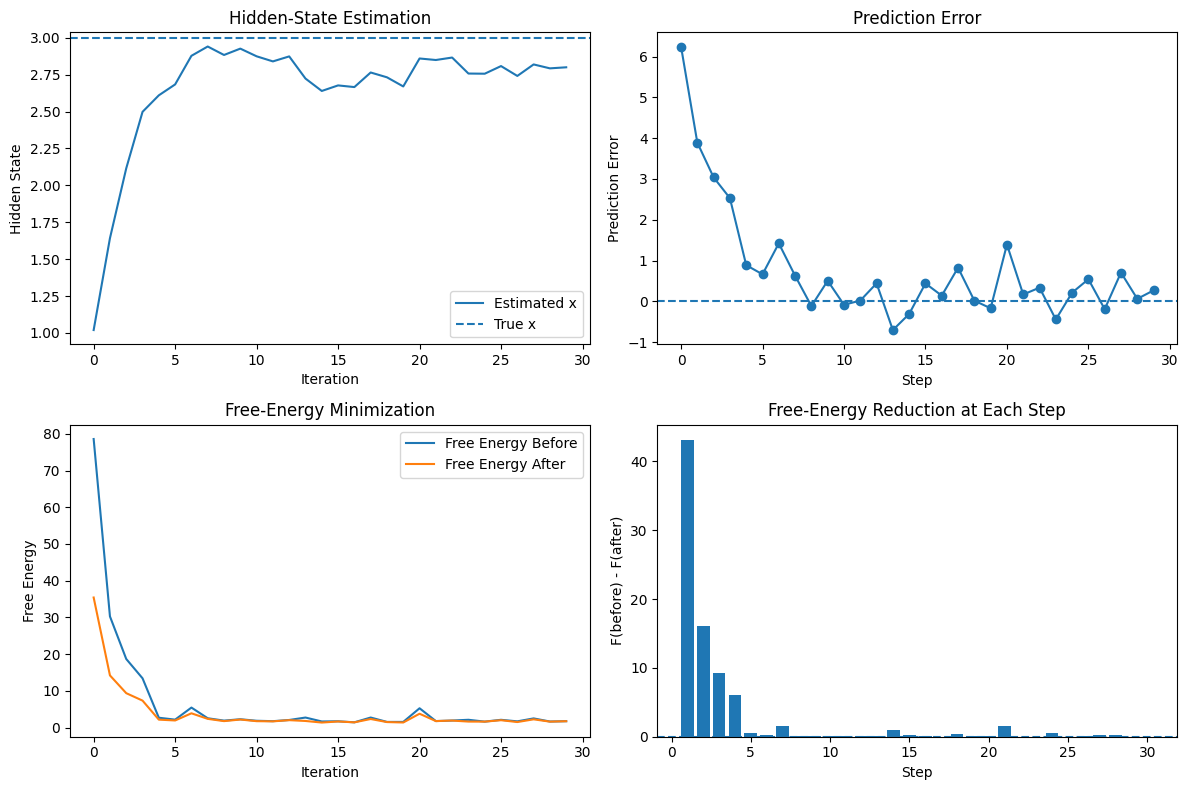

In [6]:
plt.figure(figsize=(12, 8))

# 1. Hidden-State Estimation
plt.subplot(2, 2, 1)
plt.plot(state_history, label="Estimated x")
plt.axhline(true_state, linestyle="--", label="True x")
plt.xlabel("Iteration")
plt.ylabel("Hidden State")
plt.title("Hidden-State Estimation")
plt.legend()

# 2. Prediction Error
plt.subplot(2, 2, 2)
plt.plot(prediction_error_history, marker="o")
plt.axhline(0, linestyle="--")
plt.xlabel("Step")
plt.ylabel("Prediction Error")
plt.title("Prediction Error")

# 3. Free-Energy Minimization
plt.subplot(2, 2, 3)
plt.plot(free_energy_before, label="Free Energy Before")
plt.plot(free_energy_after, label="Free Energy After")
plt.xlabel("Iteration")
plt.ylabel("Free Energy")
plt.title("Free-Energy Minimization")
plt.legend()

# 4. Free-Energy Reduction
plt.subplot(2, 2, 4)
plt.bar(
    range(1, len(free_energy_reduction) + 1),
    free_energy_reduction
)
plt.axhline(0, linestyle="--")
plt.xlabel("Step")
plt.ylabel("F(before) - F(after)")
plt.title("Free-Energy Reduction at Each Step")

plt.tight_layout()
plt.show()

## 7. Final Results

The final estimate can be compared with the actual hidden state.

The important result is that the system starts with an incorrect belief and
updates this belief using sensory prediction errors and free-energy
minimization.

In [7]:
print("True hidden state:       ", true_state)
print("Final estimated state:   ", round(x, 3))
print("Initial free energy:     ", round(free_energy_before[0], 3))
print("Final free energy:       ", round(free_energy_after[-1], 3))
print("Total free-energy change:", round(free_energy_before[0] - free_energy_after[-1], 3))

True hidden state:        3.0
Final estimated state:    2.8
Initial free energy:      78.584
Final free energy:        1.749
Total free-energy change: 76.835


The model successfully reduced its free energy from 78.584 to 1.749 by updating its estimate of the hidden state from 0 to approximately 2.8. Since the true hidden state was 3.0, the final estimate moved close to the actual hidden cause of the sensory observations. This demonstrates the core idea of perceptual inference: prediction errors are used to update internal beliefs, resulting in a better explanation of sensory observations and lower free energy.

## 8. Active Inference: Minimizing Free Energy Through Action

Perception reduces
free energy by changing **beliefs** ($x$) to better fit the sensory data. But
the free-energy principle argues the brain has a second lever: it can change
the sensory data itself by **acting on the world**, so that observations
come to match predictions instead of the other way around. This is
**active inference**.

Formally, free energy is a function of both internal beliefs $x$ and action
$a$ (through its effect on the sampled data $y$):

$$
F(x,a) = \tfrac12\Pi_y\big(y(a)-Wx\big)^2+\tfrac12\Pi_x(x-\mu)^2
$$

Gradient descent on $a$ (rather than $x$) reduces free energy by moving the
*world*, not the belief:

$$
a_{new}=a_{old}-\eta_a\frac{\partial F}{\partial a}
=a_{old}-\eta_a\frac{\partial y}{\partial a}\,\Pi_y\big(y-Wx\big)
$$


The perception step updates the agent's belief, while the action step modifies the environment to reduce sensory prediction error. This is a simplified computational demonstration of active inference.

In [8]:
np.random.seed(42)

# Initial belief and environment
x_ai = 0.0
environment_state = true_state

action_learning_rate = 0.01

state_history_ai = []
environment_history = []
free_energy_history_ai = []

# Initial observation and free energy
y = W * environment_state + np.random.normal(0, sensory_noise)
initial_free_energy = free_energy(x_ai, y)

for step in range(30):

    # 1. Observation
    y = W * environment_state + np.random.normal(0, sensory_noise)

    # 2. Prediction
    prediction = W * x_ai

    # 3. Prediction error
    prediction_error = y - prediction

    # 4. Perception: update belief
    dF_dx = (
        -W * sensory_precision * prediction_error
        + prior_precision * (x_ai - prior_mean)
    )

    x_ai = x_ai - learning_rate * dF_dx

    # 5. Action: change environment
    dF_denv = W * sensory_precision * prediction_error
    environment_state = environment_state - action_learning_rate * dF_denv

    # 6. Store results
    F_now = free_energy(x_ai, y)

    state_history_ai.append(x_ai)
    environment_history.append(environment_state)
    free_energy_history_ai.append(F_now)

print("Initial environment state:", true_state)
print("Final belief:", round(x_ai, 3))
print("Final environment state:", round(environment_state, 3))
print("Initial free energy:", round(initial_free_energy, 3))
print("Final free energy:", round(free_energy_history_ai[-1], 3))

Initial environment state: 3.0
Final belief: 1.752
Final environment state: 1.901
Initial free energy: 78.584
Final free energy: 0.283


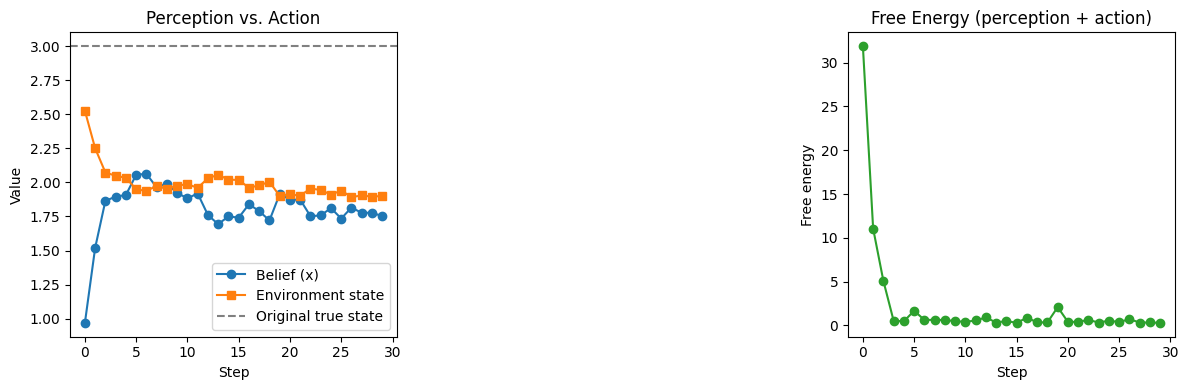

In [9]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.plot(state_history_ai, marker="o", label="Belief (x)")
plt.plot(environment_history, marker="s", label="Environment state")
plt.axhline(true_state, linestyle="--", color="gray", label="Original true state")
plt.xlabel("Step")
plt.ylabel("Value")
plt.title("Perception vs. Action")
plt.legend()


plt.subplot(1, 3, 3)
plt.plot(free_energy_history_ai, marker="o", color="tab:green")
plt.xlabel("Step")
plt.ylabel("Free energy")
plt.title("Free Energy (perception + action)")

plt.tight_layout()
plt.show()

Notice the environment state itself is pulled toward what the model expects, in addition to the belief being pulled toward the environment. This bidirectional pull is the defining feature of active inference.

## 9. Hierarchical Predictive Coding

The paper's proposed neural implementation is **hierarchical**: the cortex is
modeled as a stack of levels, where each level tries to predict the level
below it.

- **Backward (top-down) connections** carry *predictions* from a higher level
  down to a lower one — these act as an **empirical prior** for the level
  below.
- **Forward (bottom-up) connections** carry *prediction errors* — the
  mismatch between what a level predicted and what it received — weighted by
  their precision.
- Each level then adjusts its own state to reduce its precision-weighted
  prediction error, and free energy is minimized simultaneously, level by
  level, throughout the hierarchy.

Below is a minimal two-level version of the same free-energy machinery used
above. Level 2's state $x_2$ generates the *prior mean* for level 1 (instead
of a fixed constant $\mu$), and level 1's state $x_1$ generates the sensory
prediction, exactly as before.

$$
y = W_1 x_1 + z_1
\qquad\qquad
x_1 \sim N(W_2 x_2,\ \sigma_1^2)
\qquad\qquad
x_2 \sim N(\mu_2,\ \sigma_2^2)
$$


In [10]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Two-level hierarchical model: x2 → x1 → y
W1 = 2.0
W2 = 1.5

true_x2 = 2.0
true_x1 = W2 * true_x2

sensory_noise_h = 0.5

# Generate sensory observations
y_obs = W1 * true_x1 + np.random.normal(0, sensory_noise_h, 30)

# Precisions
pi_y = 1 / sensory_noise_h**2
pi_1 = 2.0
pi_2 = 1.0

# Prior and initial beliefs
mu2 = 0.0
x1, x2 = 0.0, 0.0
lr_h = 0.02

# Store inference history
x1_hist = []
x2_hist = []
F_hist = []


# Calculate hierarchical Free Energy
def hierarchical_free_energy(x1, x2, y):

    err_y = y - W1 * x1
    err_1 = x1 - W2 * x2
    err_2 = x2 - mu2

    F = (
        0.5 * pi_y * err_y**2
        + 0.5 * pi_1 * err_1**2
        + 0.5 * pi_2 * err_2**2
    )

    return F


# Hierarchical inference
for y in y_obs:

    # Prediction errors
    err_y = y - W1 * x1
    err_1 = x1 - W2 * x2

    # Update level 1
    dF_dx1 = -W1 * pi_y * err_y + pi_1 * err_1
    x1 = x1 - lr_h * dF_dx1

    # Update level 2
    dF_dx2 = -W2 * pi_1 * err_1 + pi_2 * (x2 - mu2)
    x2 = x2 - lr_h * dF_dx2

    # Store results
    x1_hist.append(x1)
    x2_hist.append(x2)

    # Calculate and store Free Energy
    F = hierarchical_free_energy(x1, x2, y)
    F_hist.append(F)


# Results
print("Hierarchical Free-Energy Minimization")
print("--------------------------------------")

print("Level 1:")
print(f"  True x1:       {true_x1:.3f}")
print(f"  Inferred x1:   {x1:.3f}")

print("\nLevel 2:")
print(f"  True x2:       {true_x2:.3f}")
print(f"  Inferred x2:   {x2:.3f}")

print("\nFree Energy:")
print(f"  Initial:       {F_hist[0]:.3f}")
print(f"  Final:         {F_hist[-1]:.3f}")

Hierarchical Free-Energy Minimization
--------------------------------------
Level 1:
  True x1:       3.000
  Inferred x1:   2.825

Level 2:
  True x2:       2.000
  Inferred x2:   1.453

Free Energy:
  Initial:       37.105
  Final:         1.556


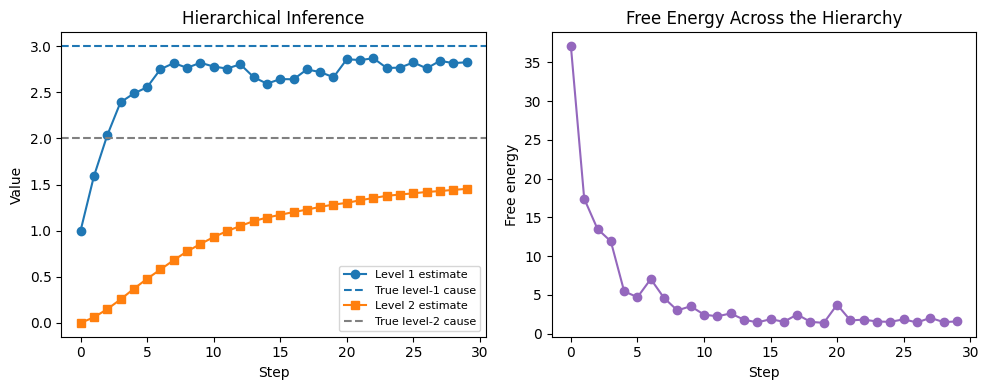

In [11]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(x1_hist, marker="o", label="Level 1 estimate")
plt.axhline(true_x1, linestyle="--", label="True level-1 cause")
plt.plot(x2_hist, marker="s", label="Level 2 estimate")
plt.axhline(true_x2, linestyle="--", color="gray", label="True level-2 cause")
plt.xlabel("Step")
plt.ylabel("Value")
plt.title("Hierarchical Inference")
plt.legend(fontsize=8)

plt.subplot(1, 2, 2)
plt.plot(F_hist, marker="o", color="tab:purple")
plt.xlabel("Step")
plt.ylabel("Free energy")
plt.title("Free Energy Across the Hierarchy")

plt.tight_layout()
plt.show()
